# Лабораторна робота: Згорткова нейронна мережа для класифікації Fashion-MNIST

**ПІБ студента:** Свіщенко Дарія Олександрівна  
**Група:** 3-9

**Дата:** 27.11.2026
### Мета роботи
Навчитися завантажувати та готувати зображення для класифікації, будувати згорткову нейронну мережу (CNN) засобами **TensorFlow / Keras**, навчати її та аналізувати результати.

### Завдання
На основі послідовності кроків у цьому шаблоні самостійно реалізуйте класифікацію зображень одягу з набору **Fashion-MNIST** (10 класів, зображення 28 × 28 пікселів). Усі комірки для коду залишено порожніми.

**Вимоги до здачі:** заповнений та виконаний `.ipynb` із виводами, графіками, прикладами прогнозів і власними висновками.

## 1. Імпорт бібліотек
Імпортуйте TensorFlow, NumPy, Matplotlib, а також потрібні модулі Keras: `Sequential`, `Input`, `Conv2D`, `MaxPooling2D`, `Dropout`, `Flatten`, `Dense`, `BatchNormalization`, `EarlyStopping`, `ReduceLROnPlateau`, `fashion_mnist`, `to_categorical`.

У вихідному прикладі також імпортовано `ImageDataGenerator`; у цій роботі він не використовується, тому його застосування необов’язкове.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Flatten, Dense, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

## 2. Завантаження даних
Завантажте **Fashion-MNIST** за допомогою `fashion_mnist.load_data()`. Збережіть навчальну та тестову вибірки у змінні `x_train`, `y_train`, `x_test`, `y_test`.

Виведіть розміри масивів, кількість класів і тип значень пікселів.

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Розмір x_train:", x_train.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір x_test:", x_test.shape)
print("Розмір y_test:", y_test.shape)
print("Кількість класів:", len(np.unique(y_train)))
print("Тип значень пікселів:", x_train.dtype)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір x_train: (60000, 28, 28)
Розмір y_train: (60000,)
Розмір x_test: (10000, 28, 28)
Розмір y_test: (10000,)
Кількість класів: 10
Тип значень пікселів: uint8


## 3. Підготовка зображень
Додайте до зображень вимір каналу: початкова форма окремого зображення `(28, 28)` повинна стати `(28, 28, 1)`. Використайте `np.expand_dims()` або еквівалентну операцію.

Перевірте результат за допомогою `.shape`.

In [3]:
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Нова форма x_train:", x_train.shape)
print("Нова форма x_test:", x_test.shape)

Нова форма x_train: (60000, 28, 28, 1)
Нова форма x_test: (10000, 28, 28, 1)


## 4. Нормалізація і кодування міток
Переведіть пікселі в тип `float32` і масштабуйте їх до діапазону **[0, 1]**. Перетворіть мітки класів на категоріальний формат за допомогою `to_categorical(..., 10)`.

Збережіть закодовані мітки як `y_train_cat` та `y_test_cat`. Перевірте діапазон пікселів і форму міток.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

num_classes = 10
y_train_cat = to_categorical(y_train, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

## 5. Візуалізація набору даних
Створіть список `class_names` з десяти назв класів у порядку Fashion-MNIST:

`T-shirt/top`, `Trouser`, `Pullover`, `Dress`, `Coat`, `Sandal`, `Shirt`, `Sneaker`, `Bag`, `Ankle boot`.

Виведіть **перші 10 зображень** навчальної вибірки в сітці **2 × 5**. Для кожного покажіть назву класу; зображення відобразіть у відтінках сірого.

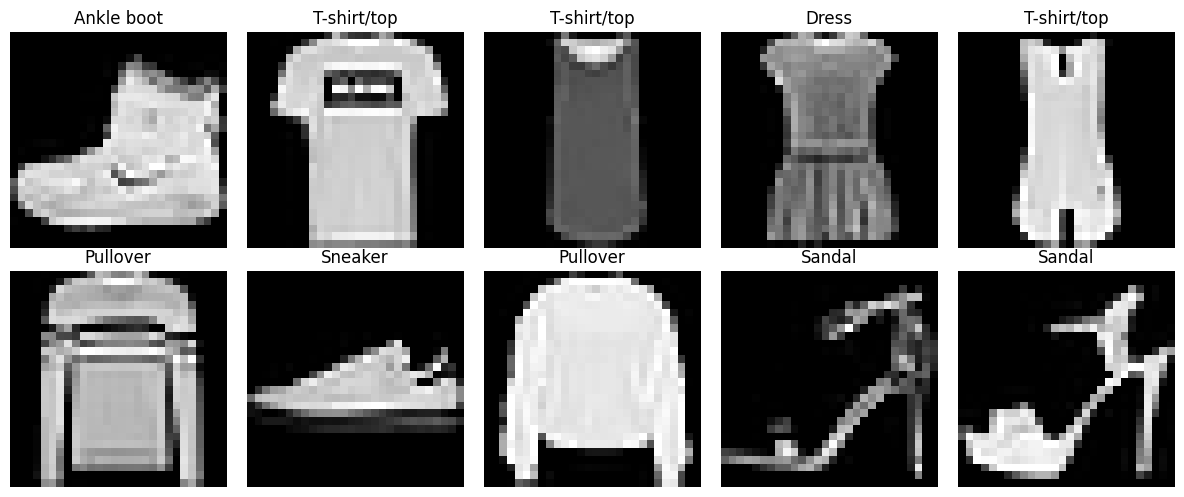

In [5]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Побудова CNN
Створіть модель `Sequential` для вхідних зображень розміру **28 × 28 × 1**. Відтворіть архітектуру з вихідного прикладу:

1. Згортковий блок: `Conv2D` з **32 фільтрами**, ядром **3 × 3**, активацією ReLU → `BatchNormalization` → `MaxPooling2D` (2 × 2) → `Dropout(0.25)`.
2. Другий аналогічний блок із **64 фільтрами**, `padding='same'`.
3. Третій аналогічний блок зі **128 фільтрами**, `padding='same'`.
4. `Flatten` → `Dense` на **512 нейронів** з ReLU → `BatchNormalization` → `Dropout(0.2)`.
5. Вихідний `Dense` на **10 нейронів** із `softmax`.

Присвойте модель змінній `model`. У комірці нижче самостійно запишіть її код.

In [6]:
model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Conv2D(128, kernel_size=(3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(512, activation="relu"),
    BatchNormalization(),
    Dropout(0.2),

    Dense(num_classes, activation="softmax")
])

## 7. Компіляція моделі та перегляд архітектури
Скомпілюйте `model` з оптимізатором **Adam**, функцією втрат **categorical crossentropy** та метрикою **accuracy**.

Виведіть `model.summary()` і визначте загальну кількість параметрів моделі.

In [7]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Загальна кількість параметрів моделі:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,082 (2.64 MB)

 Trainable params: 689,610 (2.63 MB)

 Non-trainable params: 1,472 (5.75 KB)

Загальна кількість параметрів моделі: 691082


## 8. Налаштування навчання
Створіть два callback-об’єкти:

- `EarlyStopping`: моніторинг `val_loss`, `patience=10`, `restore_best_weights=True`.
- `ReduceLROnPlateau`: моніторинг `val_loss`, `factor=0.2`, `patience=3`, `min_lr=1e-6`.

Навчіть модель методом `fit()` із `batch_size=128`, `epochs=100`. Збережіть історію навчання у змінній `history`.

**Методична примітка:** у вихідному ноутбуці тестова вибірка використана як валідаційна. Для коректної незалежної фінальної оцінки рекомендовано виділити валідаційні дані **з навчальної вибірки** (наприклад, через `validation_split=0.1`) і залишити `x_test`, `y_test_cat` лише для розділу 9.

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6
)

history = model.fit(
    x_train, y_train_cat,
    batch_size=128,
    epochs=100,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 133s 307ms/step - accuracy: 0.8102 - loss: 0.5354 - val_accuracy: 0.5513 - val_loss: 1.4042 - learning_rate: 0.0010
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 133s 287ms/step - accuracy: 0.8736 - loss: 0.3459 - val_accuracy: 0.8757 - val_loss: 0.3439 - learning_rate: 0.0010
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 290ms/step - accuracy: 0.8890 - loss: 0.3006 - val_accuracy: 0.9037 - val_loss: 0.2545 - learning_rate: 0.0010
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 292ms/step - accuracy: 0.8986 - loss: 0.2728 - val_accuracy: 0.9053 - val_loss: 0.2447 - learning_rate: 0.0010
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 121s 287ms/step - accuracy: 0.9039 - loss: 0.2568 - val_accuracy: 0.9185 - val_loss: 0.2232 - learning_rate: 0.0010
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 288ms/step - accuracy: 0.9092 - loss: 0.2422 - val_accuracy: 0.9150 - val_loss: 0.2315 - learning_rate: 0.0010
Epoch 7/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 292ms/step -

## 9. Оцінка на тестових даних і збереження моделі
Оцініть якість навченої моделі на `x_test` та `y_test_cat` за допомогою `model.evaluate()`. Виведіть `test_loss` і `test_acc`.

Збережіть модель у файл **`fashion_mnist_model.keras`**.

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=1)
print(f"test_loss: {test_loss:.4f}")
print(f"test_acc:  {test_acc:.4f}")

model.save("fashion_mnist_model.keras")
print("Модель збережено у файл fashion_mnist_model.keras")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9349 - loss: 0.1905
test_loss: 0.1905
test_acc:  0.9349
Модель збережено у файл fashion_mnist_model.keras


## 10. Графіки процесу навчання
За даними `history.history` побудуйте **два графіки поруч**:

- `accuracy` та `val_accuracy` за епохами;
- `loss` та `val_loss` за епохами.

Додайте заголовки, підписи осей, легенду та сітку. Опишіть, чи є ознаки перенавчання.

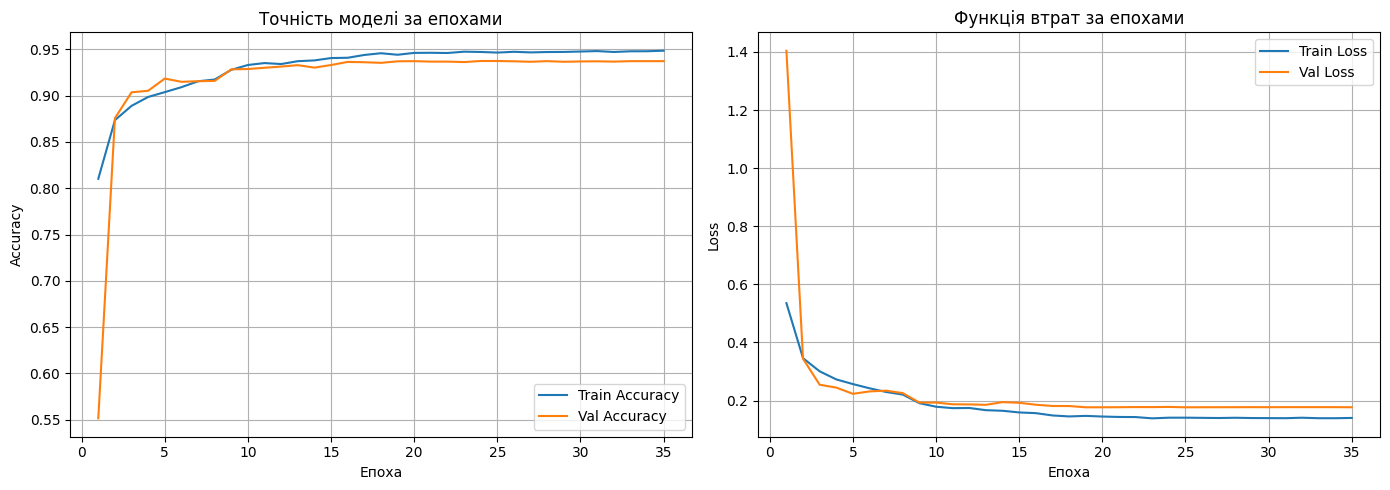

In [10]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Графік точності
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Train Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Val Accuracy")
plt.title("Точність моделі за епохами")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Графік функції втрат
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Train Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Val Loss")
plt.title("Функція втрат за епохами")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Прогнозування для випадкових зображень
Використайте `model.predict()` для отримання ймовірностей класів на тестовій вибірці. Знайдіть передбачені класи за допомогою `np.argmax()`.

Випадково оберіть **10 тестових зображень** без повторень і виведіть їх у сітці **2 × 5**. Для кожного вкажіть **істинний клас (True)** і **прогноз (Pred)**. Розгляньте приклади правильних та помилкових класифікацій.

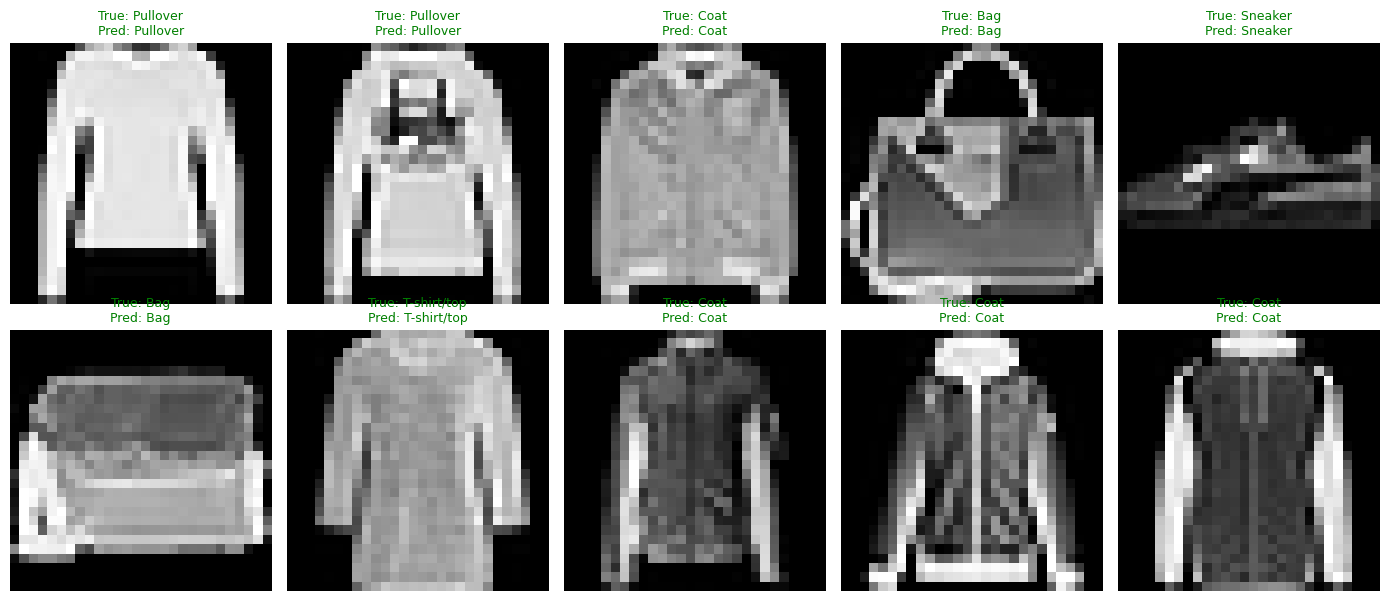

In [11]:
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

rng = np.random.default_rng()
indices = rng.choice(len(x_test), size=10, replace=False)

plt.figure(figsize=(14, 6))
for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred[idx]]
    color = "green" if y_test[idx] == y_pred[idx] else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 12. Висновки
Напишіть **власний** висновок (5–8 речень), спираючись на фактично отримані результати.

Дайте відповіді на запитання:

1. Якої точності досягнуто на тестовій вибірці?
2. Як змінювалися функція втрат і точність під час навчання? Чи є ознаки перенавчання?
3. Які класи модель плутає найчастіше серед переглянутих прикладів?
4. Для чого в архітектурі використовуються `BatchNormalization`, `MaxPooling2D` і `Dropout`?
5. Що можна змінити, аби покращити якість моделі?

**Ваш висновок:**
Під час виконання лабораторної роботи для класифікації зображень одягу з набору Fashion-MNIST було реалізовано та навчено згорткову нейронну мережу (CNN) з трьома згортковими блоками (32, 64 та 128 фільтрів) і повнозв'язним шаром на 512 нейронів. На тестовій вибірці навчена модель досягла точності 0.9349 (93,49%) при значенні функції втрат 0.1905. За графіками навчання видно, що точність на навчальній та валідаційній вибірках стрімко зростала на перших епохах і вийшла на плато близько 0,95 та 0,937 відповідно, а втрати знизилися приблизно до 0,14–0,18. Оскільки розрив між кривими невеликий, а val_loss не зростає наприкінці навчання, виражених ознак перенавчання не спостерігається, чому також сприяли EarlyStopping та ReduceLROnPlateau. Серед десяти випадково обраних тестових прикладів модель правильно розпізнала всі зображення (Pullover, Coat, Bag, Sneaker, T-shirt/top), тож явних помилок на цій вибірці не виникло, хоча у Fashion-MNIST найчастіше плутаються візуально схожі класи верхнього одягу. У побудованій архітектурі BatchNormalization стабілізує та прискорює навчання, MaxPooling2D зменшує просторову розмірність карт ознак і підвищує стійкість до малих зсувів, а Dropout знижує ризик перенавчання; для подальшого підвищення якості можна застосувати аугментацію даних і додатково підібрати гіперпараметри.